In [70]:
#import libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression

from xgboost import XGBRegressor

import joblib

In [71]:
pd.read_csv(r"D:\vs\final project1\EHR\outcomes.csv")

,patient_id,admission_date,discharge_date,length_of_stay_days,icu_admission,icu_days,in_hospital_death,discharge_disposition,readmitted_30d,days_to_readmission,primary_drg,total_charges_usd
0,P0000002,2024-08-06,2024-08-09,3,0,0,0,home_health,0,NaN,291,8589.79
1,P0000003,2022-05-06,2022-05-08,2,0,0,0,hospice,1,28.0,392,22628.17
2,P0000011,2021-12-30,2022-01-08,9,0,0,0,rehab,0,NaN,392,27565.97
3,P0000014,2022-06-30,2022-07-04,4,0,0,0,home,0,NaN,194,10332.33
4,P0000040,2020-09-19,2020-09-20,1,0,0,0,rehab,0,NaN,470,2389.61
...,...,...,...,...,...,...,...,...,...,...,...,...
10996,P0099972,2019-10-07,2019-10-25,18,0,0,0,home,0,NaN,392,15017.53
10997,P0099984,2023-11-01,2023-11-05,4,0,0,0,home,0,NaN,392,34502.78
10998,P0099991,2024-09-12,2024-09-17,5,0,0,0,home_health,0,NaN,194,32636.67
10999,P0099992,2018-06-22,2018-06-27,5,0,0,0,home_health,0,NaN,292,3082.48


In [72]:
df = pd.read_csv(r"D:\vs\final project1\EHR\outcomes.csv")

In [73]:
df.shape

(11001, 12)

In [74]:
df.columns

Index(['patient_id', 'admission_date', 'discharge_date', 'length_of_stay_days',
       'icu_admission', 'icu_days', 'in_hospital_death',
       'discharge_disposition', 'readmitted_30d', 'days_to_readmission',
       'primary_drg', 'total_charges_usd'],
      dtype='object')

In [75]:
df.head()

,patient_id,admission_date,discharge_date,length_of_stay_days,icu_admission,icu_days,in_hospital_death,discharge_disposition,readmitted_30d,days_to_readmission,primary_drg,total_charges_usd
0,P0000002,2024-08-06,2024-08-09,3,0,0,0,home_health,0,NaN,291,8589.79
1,P0000003,2022-05-06,2022-05-08,2,0,0,0,hospice,1,28.0,392,22628.17
2,P0000011,2021-12-30,2022-01-08,9,0,0,0,rehab,0,NaN,392,27565.97
3,P0000014,2022-06-30,2022-07-04,4,0,0,0,home,0,NaN,194,10332.33
4,P0000040,2020-09-19,2020-09-20,1,0,0,0,rehab,0,NaN,470,2389.61


In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11001 entries, 0 to 11000
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   patient_id             11001 non-null  object 
 1   admission_date         11001 non-null  object 
 2   discharge_date         11001 non-null  object 
 3   length_of_stay_days    11001 non-null  int64  
 4   icu_admission          11001 non-null  int64  
 5   icu_days               11001 non-null  int64  
 6   in_hospital_death      11001 non-null  int64  
 7   discharge_disposition  11001 non-null  object 
 8   readmitted_30d         11001 non-null  int64  
 9   days_to_readmission    1643 non-null   float64
 10  primary_drg            11001 non-null  int64  
 11  total_charges_usd      11001 non-null  float64
dtypes: float64(2), int64(6), object(4)
memory usage: 1.0+ MB


In [77]:
#Check Missing Values
df.isnull().sum()

patient_id                  0
admission_date              0
discharge_date              0
length_of_stay_days         0
icu_admission               0
icu_days                    0
in_hospital_death           0
discharge_disposition       0
readmitted_30d              0
days_to_readmission      9358
primary_drg                 0
total_charges_usd           0
dtype: int64

In [78]:
df = df.drop('days_to_readmission', axis=1)

In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11001 entries, 0 to 11000
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   patient_id             11001 non-null  object 
 1   admission_date         11001 non-null  object 
 2   discharge_date         11001 non-null  object 
 3   length_of_stay_days    11001 non-null  int64  
 4   icu_admission          11001 non-null  int64  
 5   icu_days               11001 non-null  int64  
 6   in_hospital_death      11001 non-null  int64  
 7   discharge_disposition  11001 non-null  object 
 8   readmitted_30d         11001 non-null  int64  
 9   primary_drg            11001 non-null  int64  
 10  total_charges_usd      11001 non-null  float64
dtypes: float64(1), int64(6), object(4)
memory usage: 945.5+ KB


In [80]:
# drop leakage columns
df = df.drop([
    'patient_id',
    'admission_date',
    'discharge_date'
], axis=1)

In [81]:
#categorical missing
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [82]:
#numeric missing
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [83]:
#Define Target
y = df['total_charges_usd']

X = df.drop('total_charges_usd', axis=1)

In [84]:
#Check Target Distribution
y.describe()

count     11001.000000
mean      18224.206764
std       17104.712382
min        2000.000000
25%        7799.640000
50%       13239.840000
75%       22523.480000
max      194181.080000
Name: total_charges_usd, dtype: float64

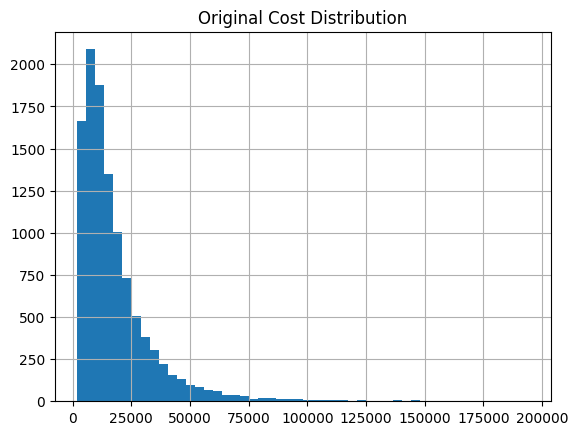

In [85]:
#Plot histogram
y.hist(bins=50)

plt.title("Original Cost Distribution")

plt.show()

In [86]:
y = np.log1p(y)

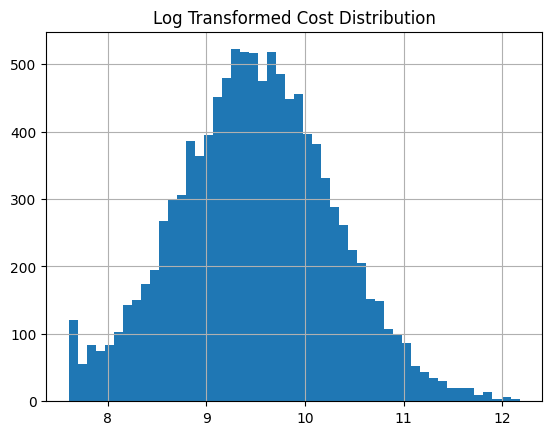

In [87]:
pd.Series(y).hist(bins=50)

plt.title("Log Transformed Cost Distribution")

plt.show()

In [88]:
#Handle categorical feature 
X['primary_drg'] = X['primary_drg'].astype(str)

In [58]:
X['primary_drg'] = X['primary_drg'].astype(str)

In [89]:
#One-Hot Encode Features
X = pd.get_dummies(X, drop_first=True)

print(X.shape)

print(X.columns)

(11001, 15)
Index(['length_of_stay_days', 'icu_admission', 'icu_days', 'in_hospital_death',
       'readmitted_30d', 'discharge_disposition_home',
       'discharge_disposition_home_health', 'discharge_disposition_hospice',
       'discharge_disposition_rehab', 'discharge_disposition_skilled_nursing',
       'primary_drg_291', 'primary_drg_292', 'primary_drg_293',
       'primary_drg_392', 'primary_drg_470'],
      dtype='object')


In [90]:
#Train/Test Split
#split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [91]:
#Baseline model
baseline = LinearRegression()

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

In [92]:
#Reverse transform
y_test_actual = np.expm1(y_test)

baseline_pred_actual = np.expm1(baseline_pred)

In [93]:
#Evaluate baseline
baseline_r2 = r2_score(
    y_test_actual,
    baseline_pred_actual
)

print("Baseline R2:", baseline_r2)

Baseline R2: -0.09203571853731152


In [94]:
#Train Model
model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

In [95]:
#Test
model.fit(X_train, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [96]:
#Predictions
y_pred = model.predict(X_test)

In [97]:
#REVERSE LOG TRANSFORM
y_pred_actual = np.expm1(y_pred)

In [98]:
#Evaluation metrics
mae = mean_absolute_error(
    y_test_actual,
    y_pred_actual
)

mse = mean_squared_error(
    y_test_actual,
    y_pred_actual
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test_actual,
    y_pred_actual
)

print("MAE:", mae)

print("RMSE:", rmse)

print("R2:", r2)

MAE: 10660.621844212326
RMSE: 17490.003089247435
R2: -0.10494269793280342


In [99]:
#Save Model
import joblib

joblib.dump(
    model,
    "cost_prediction_model.pkl"
)

joblib.dump(
    X_train.columns,
    "cost_prediction_columns.pkl"
)

['cost_prediction_columns.pkl']

In [100]:
#Create Prediction Function
def prepare_cost_input(input_dict):

    import pandas as pd
    import joblib

    cols = joblib.load(
        "cost_prediction_columns.pkl"
    )

    df = pd.DataFrame([input_dict])

    df['primary_drg'] = df[
        'primary_drg'
    ].astype(str)

    df = pd.get_dummies(df)

    df = df.reindex(
        columns=cols,
        fill_value=0
    )

    return df

In [101]:
#Final Cost Prediction Function
def predict_cost(input_dict):

    import numpy as np

    sample = prepare_cost_input(
        input_dict
    )

    pred_log = model.predict(sample)[0]

    pred_cost = np.expm1(pred_log)

    return round(pred_cost, 2)

In [102]:
#Explainability Function
def explain_cost(sample):

    reasons = []

    if sample['icu_days'].values[0] > 0:
        reasons.append(
            "ICU utilization increased treatment cost"
        )

    if sample[
        'length_of_stay_days'
    ].values[0] > 5:

        reasons.append(
            "Long hospital stay increased billing"
        )

    if sample[
        'readmitted_30d'
    ].values[0] == 1:

        reasons.append(
            "Readmission-related care increased cost"
        )

    return reasons

In [103]:
#Test With Sample Patient
sample_patient = {

    'length_of_stay_days': 6,

    'icu_admission': 1,

    'icu_days': 3,

    'in_hospital_death': 0,

    'readmitted_30d': 1,

    'primary_drg': '291',

    'discharge_disposition': 'home'
}

In [104]:
#Final System Test
predicted_cost = predict_cost(
    sample_patient
)

print(
    "Predicted Cost:",
    predicted_cost
)

Predicted Cost: 10789.4


In [105]:
#Generate Explanation
sample = prepare_cost_input(
    sample_patient
)

print(
    "Reasons:",
    explain_cost(sample)
)

Reasons: ['ICU utilization increased treatment cost', 'Long hospital stay increased billing', 'Readmission-related care increased cost']
